# 01 · Exploratory analysis
**Question:** what does normal ad performance look like, and how much spend goes to ads after they have fatigued?

Input: `data/processed/ad_daily_features.csv` (built by `src/build_dataset.py`). Data is **simulated** (see `src/simulate_data.py`).

In [1]:
# cell 1: load
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent                     # notebooks/ -> project root
FIG = ROOT / "reports" / "figures"
df = pd.read_csv(ROOT / "data/processed/ad_daily_features.csv", parse_dates=["date", "launch_date"])
summary = pd.read_csv(ROOT / "data/processed/ad_summary.csv")
print(df.shape, df["ad_id"].nunique(), "ads")
print(df["date"].min().date(), "to", df["date"].max().date())

(2795, 28) 114 ads
2026-07-02 to 2026-09-28


## Headline numbers

In [2]:
# cell 2: headline numbers
total_spend = df["spend_inr"].sum()
fatigued_spend = df.loc[df["is_fatigued"] == 1, "spend_inr"].sum()
print(f"Total spend: ₹{total_spend:,.0f}")
print(f"Spend on fatigued ad-days: ₹{fatigued_spend:,.0f} ({fatigued_spend / total_spend:.0%})")

Total spend: ₹9,523,063
Spend on fatigued ad-days: ₹3,158,830 (33%)


**So what:** about a third of all spend went to ads on days when they had already fatigued.

## Performance by format

In [3]:
# cell 3: performance by format
by_format = (df.groupby("format")
               .agg(ads=("ad_id", "nunique"),
                    spend_inr=("spend_inr", "sum"),
                    median_ctr=("ctr_pct", "median"),
                    median_cpm=("cpm_inr", "median"))
               .sort_values("median_ctr", ascending=False)
               .round(2))
by_format

,ads,spend_inr,median_ctr,median_cpm
format,,,,
song,22,1649727.40,1.07,95.24
street_interview,23,2258710.53,1.04,105.44
drama,20,2470858.00,0.93,83.52
ugc,36,2024475.62,0.86,95.50
podcast,13,1119291.10,0.77,96.61


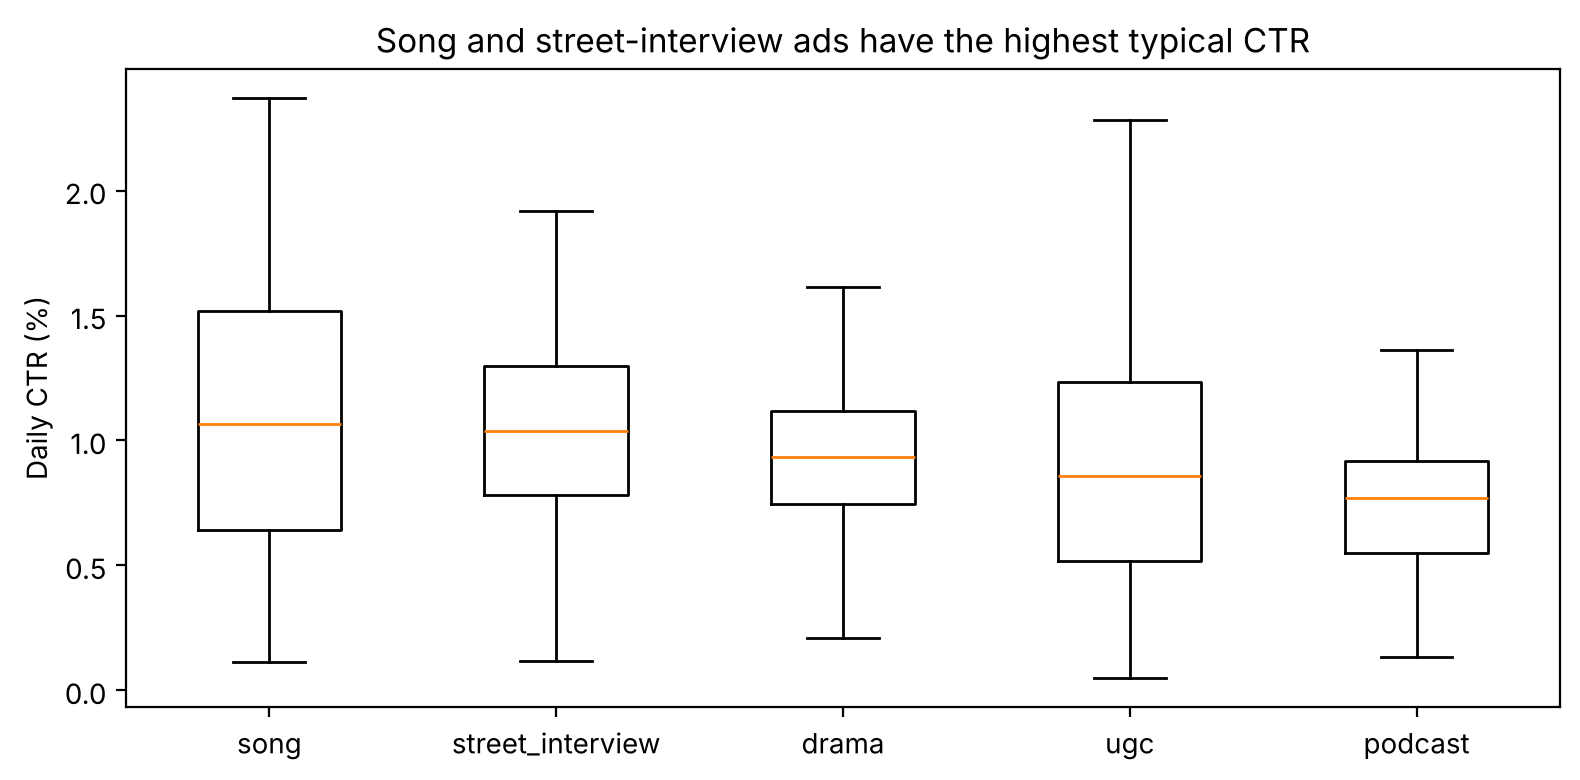

In [4]:
# cell 4: CTR distribution by format
order = by_format.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df.loc[df["format"] == f, "ctr_pct"] for f in order], tick_labels=order, showfliers=False)
ax.set_ylabel("Daily CTR (%)")
ax.set_title("Song and street-interview ads have the highest typical CTR")
plt.tight_layout(); plt.savefig(FIG / "eda_ctr_by_format.png", dpi=150); plt.show()

**So what:** song and street-interview ads have the highest typical CTR; podcast the lowest. Raw CTR alone doesn't show *how long* each format lasts. That's the next notebook.

## Day of week

In [5]:
# cell 5: day of week
dow = df.assign(day=df["date"].dt.day_name()).groupby("day")["ctr_pct"].median()
dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).round(3)

day
Monday       0.947
Tuesday      0.964
Wednesday    0.954
Thursday     0.945
Friday       0.955
Saturday     0.874
Sunday       0.874
Name: ctr_pct, dtype: float64

**So what:** weekend CTR is about 8% lower than weekdays. A single weekend dip is not fatigue, which is why the project uses 3-day rolling averages.

## Frequency vs CTR

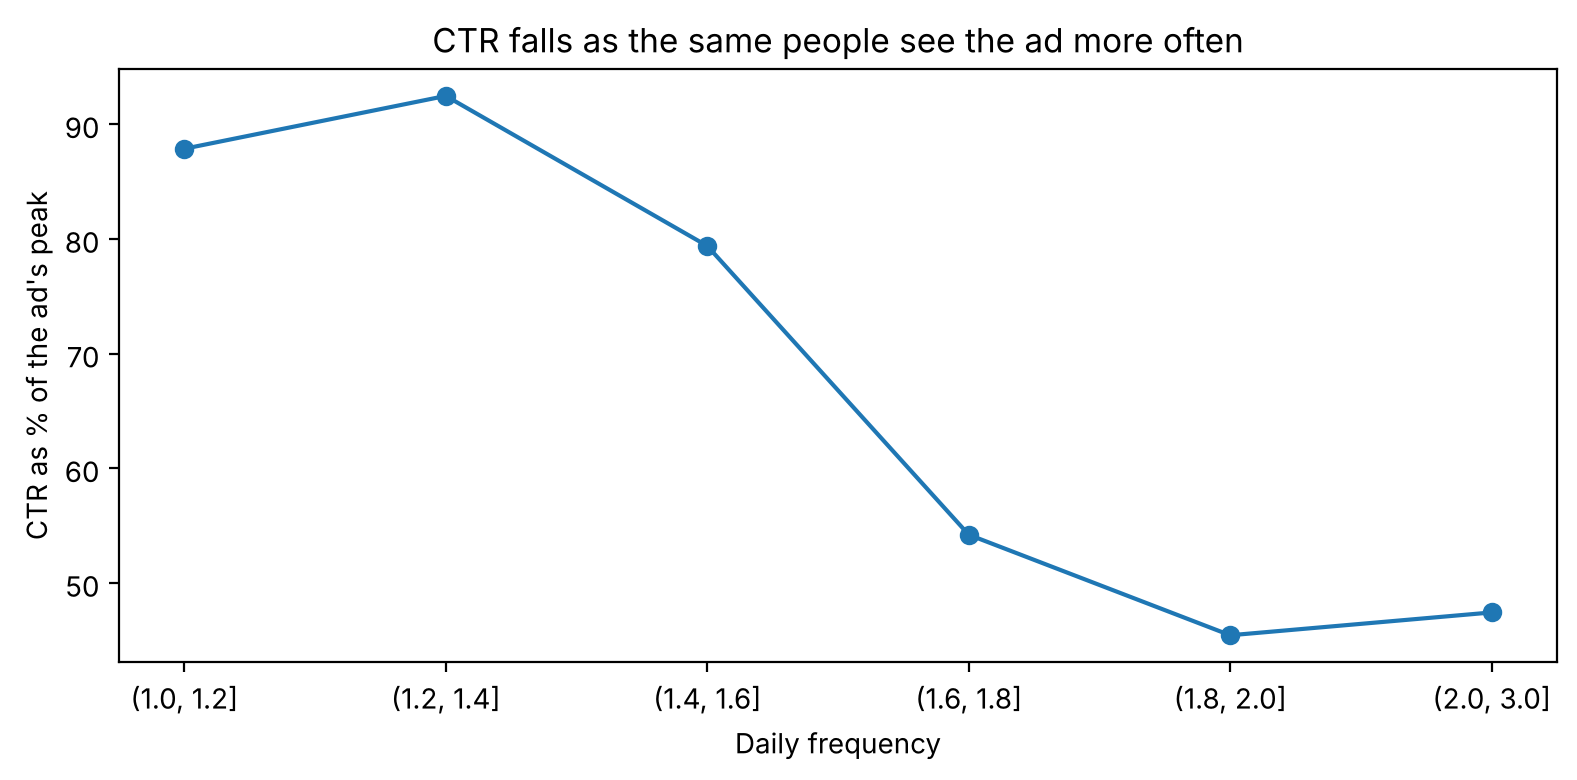

correlation: -0.65


In [6]:
# cell 6: frequency vs CTR (as % of each ad's own peak)
df["ctr_pct_of_peak"] = df["ctr_roll3"] / df.groupby("ad_id")["ctr_roll3"].transform("max")
bins = pd.cut(df["frequency"], bins=[1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 3.0])
freq_curve = df.groupby(bins, observed=True)["ctr_pct_of_peak"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([str(b) for b in freq_curve.index], freq_curve.values * 100, marker="o")
ax.set_xlabel("Daily frequency"); ax.set_ylabel("CTR as % of the ad's peak")
ax.set_title("CTR falls as the same people see the ad more often")
plt.tight_layout(); plt.savefig(FIG / "eda_frequency_vs_ctr.png", dpi=150); plt.show()
print("correlation:", df[["frequency", "ctr_pct_of_peak"]].corr().iloc[0, 1].round(2))

**So what:** once daily frequency passes about 1.6, CTR falls to roughly half of the ad's own peak (correlation −0.65). Seeing the same ad again and again is what drives fatigue.